=== Результати для SLIC ===
Час виконання: 0.127 сек
Boundary Recall (BR): 0.5649 (чим вище, тим краще)
Undersegmentation Error (UE): 0.1697 (чим нижче, тим краще)


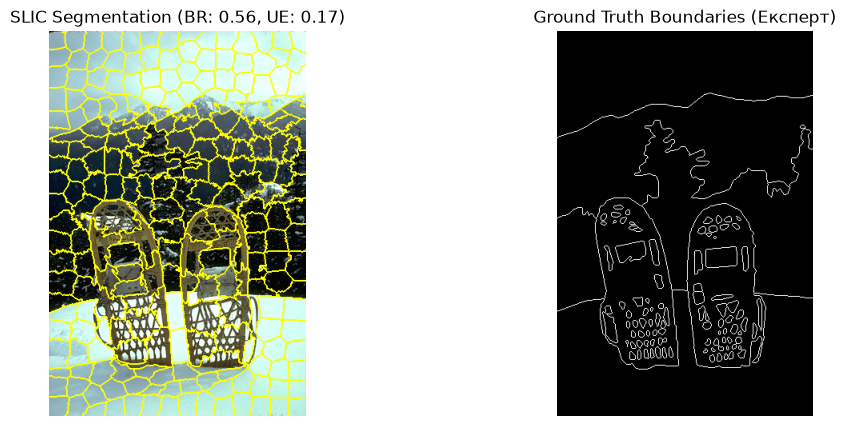

In [2]:
import os
import cv2
import matplotlib.pyplot as plt
from skimage.segmentation import slic, mark_boundaries
import metrics  # Наш файл metrics.py

# 1. Шляхи до файлів
image_id = "2018"  # Заміни на номер картинки, яку ти закинув
img_path = f"data/raw/{image_id}.jpg"
gt_path = f"data/ground_truth/{image_id}.mat"

if os.path.exists(img_path) and os.path.exists(gt_path):
    # 2. Завантажуємо зображення та розмітку
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    gt_segmentations, gt_boundaries = metrics.load_bsds500_gt(gt_path)
    # Беремо розмітку першого експерта для тесту
    first_gt_seg = gt_segmentations[0]
    first_gt_bound = gt_boundaries[0]
    
    # 3. Запускаємо SLIC
    labels_slic, time_slic = metrics.benchmark_algorithm(slic, img, n_segments=300, compactness=10, start_label=1)
    
    # 4. Рахуємо метрики
    br = metrics.compute_boundary_recall(first_gt_bound, labels_slic, tolerance=2)
    ue = metrics.compute_undersegmentation_error(first_gt_seg, labels_slic)
    
    print(f"=== Результати для SLIC ===")
    print(f"Час виконання: {time_slic:.3f} сек")
    print(f"Boundary Recall (BR): {br:.4f} (чим вище, тим краще)")
    print(f"Undersegmentation Error (UE): {ue:.4f} (чим нижче, тим краще)")
    
    # 5. Візуалізація
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(mark_boundaries(img, labels_slic))
    axes[0].set_title(f"SLIC Segmentation (BR: {br:.2f}, UE: {ue:.2f})")
    
    axes[1].imshow(first_gt_bound, cmap='gray')
    axes[1].set_title("Ground Truth Boundaries (Експерт)")
    
    for ax in axes:
        ax.axis('off')
    plt.show()
else:
    print(f"Файли {img_path} або {gt_path} не знайдено! Перевір назви у папках data/raw та data/ground_truth.")

=== Порівняльна таблиця результатів ===
   Algorithm     Time       BR       UE
        SLIC 0.103425 0.564893 0.169720
Felzenszwalb 0.132077 0.861575 0.105485
  Quickshift 0.566363 0.946397 0.100343
   Watershed 0.042265 0.666798 0.151502


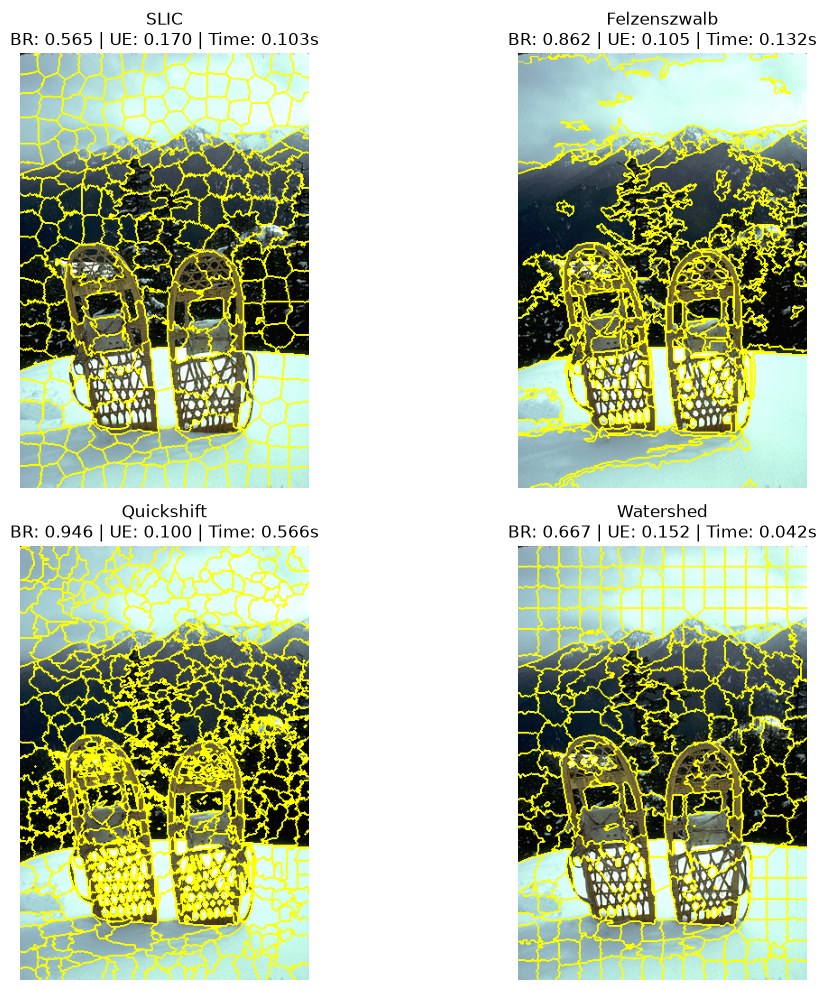

In [4]:
import os
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from skimage.segmentation import slic, felzenszwalb, quickshift, watershed, mark_boundaries
from skimage.filters import sobel
from skimage.color import rgb2gray
import metrics

# 1. Завантаження кадру
image_id = "2018"  # або будь-який інший ID
img_path = f"data/raw/{image_id}.jpg"
gt_path = f"data/ground_truth/{image_id}.mat"

img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gt_segmentations, gt_boundaries = metrics.load_bsds500_gt(gt_path)
gt_seg = gt_segmentations[0]
gt_bound = gt_boundaries[0]

# 2. Запуск 4 алгоритмів
results = []

# SLIC
labels_slic, t_slic = metrics.benchmark_algorithm(slic, img, n_segments=300, compactness=10, start_label=1)
results.append({
    'Algorithm': 'SLIC', 'Labels': labels_slic, 'Time': t_slic,
    'BR': metrics.compute_boundary_recall(gt_bound, labels_slic),
    'UE': metrics.compute_undersegmentation_error(gt_seg, labels_slic)
})

# Felzenszwalb
labels_felz, t_felz = metrics.benchmark_algorithm(felzenszwalb, img, scale=100, sigma=0.5, min_size=50)
results.append({
    'Algorithm': 'Felzenszwalb', 'Labels': labels_felz, 'Time': t_felz,
    'BR': metrics.compute_boundary_recall(gt_bound, labels_felz),
    'UE': metrics.compute_undersegmentation_error(gt_seg, labels_felz)
})

# Quickshift
labels_quick, t_quick = metrics.benchmark_algorithm(quickshift, img, kernel_size=3, max_dist=6, ratio=0.5)
results.append({
    'Algorithm': 'Quickshift', 'Labels': labels_quick, 'Time': t_quick,
    'BR': metrics.compute_boundary_recall(gt_bound, labels_quick),
    'UE': metrics.compute_undersegmentation_error(gt_seg, labels_quick)
})

# Watershed
gradient = sobel(rgb2gray(img))
labels_water, t_water = metrics.benchmark_algorithm(watershed, gradient, markers=300, compactness=0.001)
results.append({
    'Algorithm': 'Watershed', 'Labels': labels_water, 'Time': t_water,
    'BR': metrics.compute_boundary_recall(gt_bound, labels_water),
    'UE': metrics.compute_undersegmentation_error(gt_seg, labels_water)
})

# 3. Вивід порівняльної таблиці
df = pd.DataFrame(results)[['Algorithm', 'Time', 'BR', 'UE']]
print("=== Порівняльна таблиця результатів ===")
print(df.to_string(index=False))

# 4. Візуалізація сіток
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for i, res in enumerate(results):
    axes[i].imshow(mark_boundaries(img, res['Labels']))
    axes[i].set_title(f"{res['Algorithm']}\nBR: {res['BR']:.3f} | UE: {res['UE']:.3f} | Time: {res['Time']:.3f}s")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [1]:
import os
import glob
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from skimage.segmentation import slic, felzenszwalb, quickshift, watershed
from skimage.filters import sobel
from skimage.color import rgb2gray
import metrics

# 1. Збираємо всі тестові файли
raw_files = glob.glob("data/raw/*.jpg")
print(f"Знайдено {len(raw_files)} зображень для пакетної обробки.")

all_results = []

for img_path in raw_files:
    image_id = os.path.splitext(os.path.basename(img_path))[0]
    gt_path = f"data/ground_truth/{image_id}.mat"
    
    if not os.path.exists(gt_path):
        print(f"Пропускаємо {image_id}: немає .mat файла розмітки")
        continue
        
    # Завантажуємо кадр та Ground Truth
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    gt_segmentations, gt_boundaries = metrics.load_bsds500_gt(gt_path)
    
    # Використовуємо розмітку першого експерта як еталон
    gt_seg = gt_segmentations[0]
    gt_bound = gt_boundaries[0]
    
    # --- SLIC ---
    lbl_slic, t_slic = metrics.benchmark_algorithm(slic, img, n_segments=300, compactness=10, start_label=1)
    br_slic = metrics.compute_boundary_recall(gt_bound, lbl_slic)
    ue_slic = metrics.compute_undersegmentation_error(gt_seg, lbl_slic)
    all_results.append({'Image_ID': image_id, 'Algorithm': 'SLIC', 'Time': t_slic, 'BR': br_slic, 'UE': ue_slic})

    # --- Felzenszwalb ---
    lbl_felz, t_felz = metrics.benchmark_algorithm(felzenszwalb, img, scale=100, sigma=0.5, min_size=50)
    br_felz = metrics.compute_boundary_recall(gt_bound, lbl_felz)
    ue_felz = metrics.compute_undersegmentation_error(gt_seg, lbl_felz)
    all_results.append({'Image_ID': image_id, 'Algorithm': 'Felzenszwalb', 'Time': t_felz, 'BR': br_felz, 'UE': ue_felz})

    # --- Quickshift ---
    lbl_quick, t_quick = metrics.benchmark_algorithm(quickshift, img, kernel_size=3, max_dist=6, ratio=0.5)
    br_quick = metrics.compute_boundary_recall(gt_bound, lbl_quick)
    ue_quick = metrics.compute_undersegmentation_error(gt_seg, lbl_quick)
    all_results.append({'Image_ID': image_id, 'Algorithm': 'Quickshift', 'Time': t_quick, 'BR': br_quick, 'UE': ue_quick})

    # --- Watershed ---
    gradient = sobel(rgb2gray(img))
    lbl_water, t_water = metrics.benchmark_algorithm(watershed, gradient, markers=300, compactness=0.001)
    br_water = metrics.compute_boundary_recall(gt_bound, lbl_water)
    ue_water = metrics.compute_undersegmentation_error(gt_seg, lbl_water)
    all_results.append({'Image_ID': image_id, 'Algorithm': 'Watershed', 'Time': t_water, 'BR': br_water, 'UE': ue_water})

# 2. Формуємо підсумковий DataFrame
df_raw = pd.DataFrame(all_results)

# Створюємо директорію results якщо її немає
os.makedirs("results", exist_ok=True)
df_raw.to_csv("results/detailed_benchmark_results.csv", index=False)

# 3. Агрегуємо результати (середнє та ст. відхилення)
summary = df_raw.groupby('Algorithm').agg(
    Mean_BR=('BR', 'mean'),
    Std_BR=('BR', 'std'),
    Mean_UE=('UE', 'mean'),
    Std_UE=('UE', 'std'),
    Mean_Time=('Time', 'mean'),
    Std_Time=('Time', 'std')
).reset_index()

summary.to_csv("results/summary_metrics.csv", index=False)
print("\n=== Підсумкова таблиця (Середні значення по всій вибірці) ===")
print(summary.to_string(index=False))

Знайдено 200 зображень для пакетної обробки.

=== Підсумкова таблиця (Середні значення по всій вибірці) ===
   Algorithm  Mean_BR   Std_BR  Mean_UE   Std_UE  Mean_Time  Std_Time
Felzenszwalb 0.888964 0.065035 0.090028 0.061514   0.121107  0.034398
  Quickshift 0.892172 0.069258 0.069121 0.037324   0.557315  0.141099
        SLIC 0.714021 0.092343 0.143055 0.068295   0.095702  0.029726
   Watershed 0.721122 0.090533 0.130184 0.061781   0.043450  0.009433


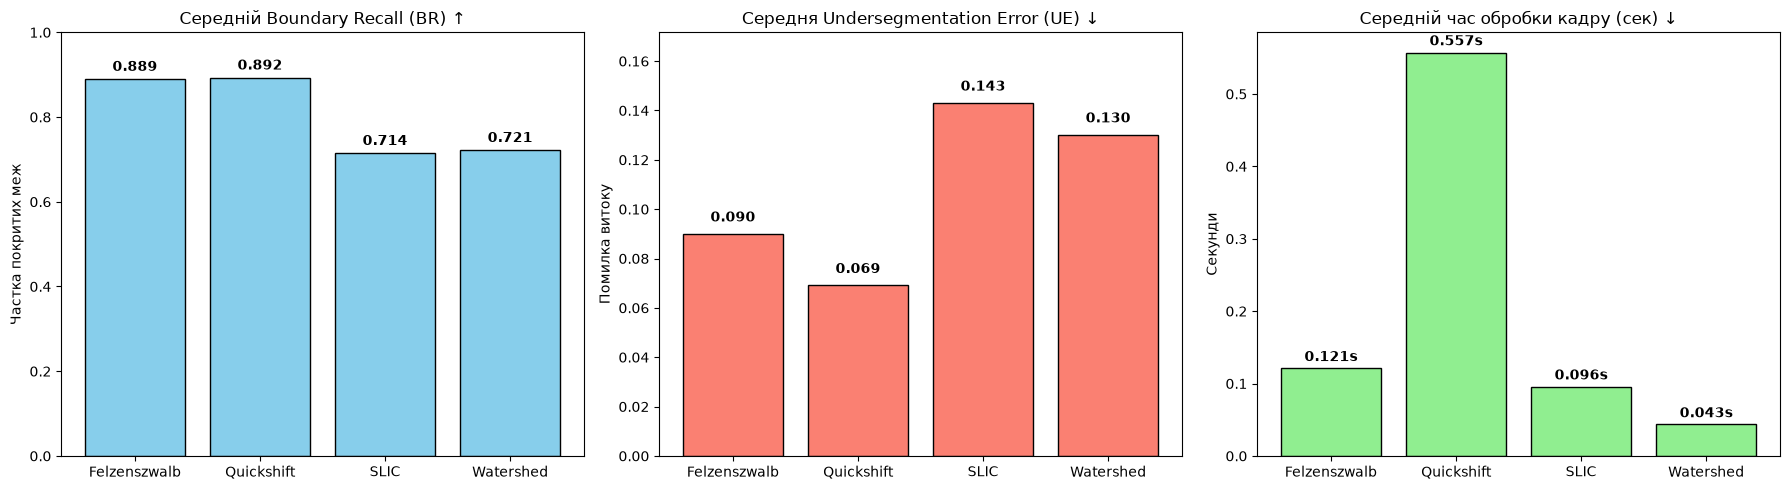

Графіки збережено в results/metrics_comparison.png


In [2]:
# Побудова порівняльних діаграм
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Графік Boundary Recall (вище = краще)
axes[0].bar(summary['Algorithm'], summary['Mean_BR'], color='skyblue', edgecolor='black')
axes[0].set_title('Середній Boundary Recall (BR) ↑')
axes[0].set_ylabel('Частка покритих меж')
axes[0].set_ylim(0, 1.0)
for i, val in enumerate(summary['Mean_BR']):
    axes[0].text(i, val + 0.02, f"{val:.3f}", ha='center', fontweight='bold')

# 2. Графік Undersegmentation Error (нижче = краще)
axes[1].bar(summary['Algorithm'], summary['Mean_UE'], color='salmon', edgecolor='black')
axes[1].set_title('Середня Undersegmentation Error (UE) ↓')
axes[1].set_ylabel('Помилка витоку')
axes[1].set_ylim(0, max(summary['Mean_UE']) * 1.2)
for i, val in enumerate(summary['Mean_UE']):
    axes[1].text(i, val + 0.005, f"{val:.3f}", ha='center', fontweight='bold')

# 3. Графік Часу виконання (нижче = краще)
axes[2].bar(summary['Algorithm'], summary['Mean_Time'], color='lightgreen', edgecolor='black')
axes[2].set_title('Середній час обробки кадру (сек) ↓')
axes[2].set_ylabel('Секунди')
for i, val in enumerate(summary['Mean_Time']):
    axes[2].text(i, val + 0.01, f"{val:.3f}s", ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig("results/metrics_comparison.png", dpi=300)
plt.show()
print("Графіки збережено в results/metrics_comparison.png")

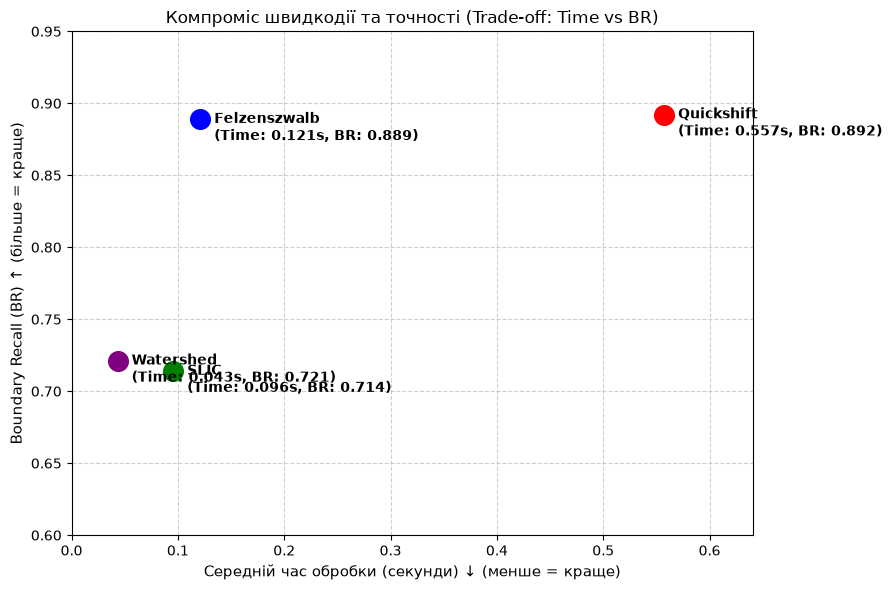

Графік Trade-Off збережено в results/tradeoff_time_vs_br.png


In [3]:
import matplotlib.pyplot as plt
import pandas as pd

# Завантажуємо збережені агреговані метрики
summary = pd.read_csv("results/summary_metrics.csv")

plt.figure(figsize=(9, 6))

# Побудова точки для кожного алгоритму
colors = {'Felzenszwalb': 'blue', 'Quickshift': 'red', 'SLIC': 'green', 'Watershed': 'purple'}

for idx, row in summary.iterrows():
    algo = row['Algorithm']
    plt.scatter(row['Mean_Time'], row['Mean_BR'], s=200, color=colors.get(algo, 'black'), label=algo, zorder=3)
    # Додаємо підписи до точок
    plt.annotate(
        f"{algo}\n(Time: {row['Mean_Time']:.3f}s, BR: {row['Mean_BR']:.3f})", 
        (row['Mean_Time'], row['Mean_BR']),
        xytext=(10, -15), textcoords='offset points', fontweight='bold'
    )

plt.title('Компроміс швидкодії та точності (Trade-off: Time vs BR)', fontsize=12)
plt.xlabel('Середній час обробки (секунди) ↓ (менше = краще)', fontsize=11)
plt.ylabel('Boundary Recall (BR) ↑ (більше = краще)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6, zorder=0)
plt.xlim(0, max(summary['Mean_Time']) * 1.15)
plt.ylim(0.6, 0.95)

plt.tight_layout()
plt.savefig("results/tradeoff_time_vs_br.png", dpi=300)
plt.show()
print("Графік Trade-Off збережено в results/tradeoff_time_vs_br.png")

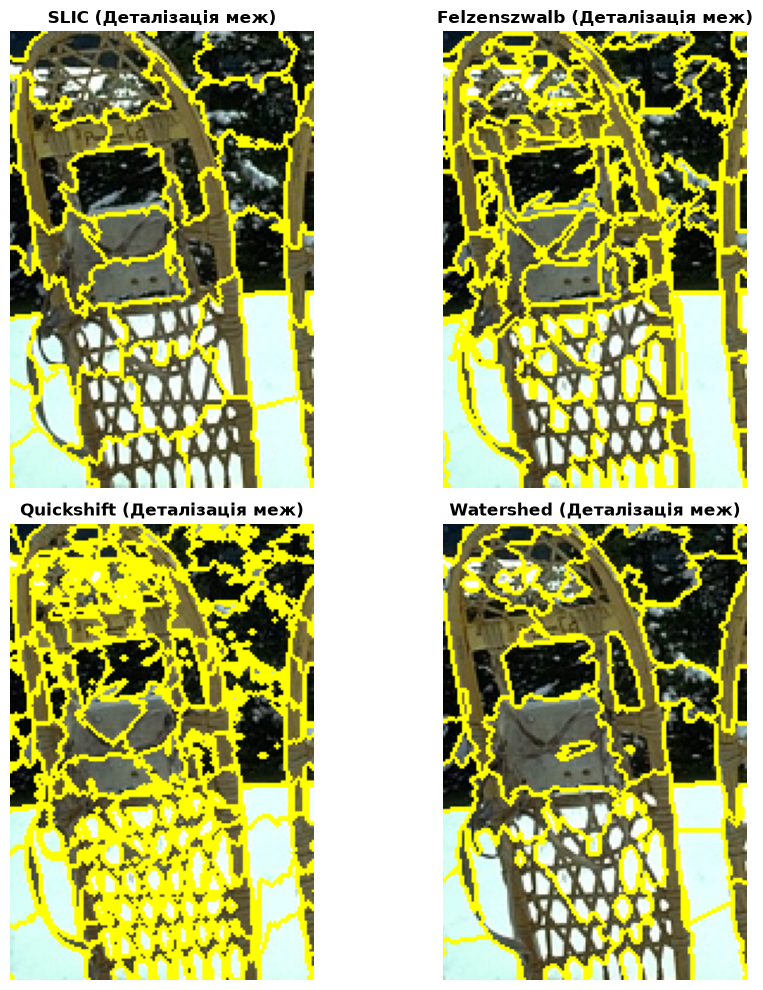

Збережено зображення деталізації в results/qualitative_crop_comparison.png


In [4]:
import cv2
import matplotlib.pyplot as plt
from skimage.segmentation import slic, felzenszwalb, quickshift, watershed, mark_boundaries
from skimage.filters import sobel
from skimage.color import rgb2gray
import metrics

# 1. Завантаження кадру
image_id = "2018"
img = cv2.cvtColor(cv2.imread(f"data/raw/{image_id}.jpg"), cv2.COLOR_BGR2RGB)

# 2. Обчислення сегментацій
lbl_slic, _ = metrics.benchmark_algorithm(slic, img, n_segments=300, compactness=10, start_label=1)
lbl_felz, _ = metrics.benchmark_algorithm(felzenszwalb, img, scale=100, sigma=0.5, min_size=50)
lbl_quick, _ = metrics.benchmark_algorithm(quickshift, img, kernel_size=3, max_dist=6, ratio=0.5)

gradient = sobel(rgb2gray(img))
lbl_water, _ = metrics.benchmark_algorithm(watershed, gradient, markers=300, compactness=0.001)

# 3. Визначаємо області кропу (Zoom-In) для деталі (наприклад, снігоступ)
# [y_min:y_max, x_min:x_max]
h, w, _ = img.shape
crop_y1, crop_y2 = int(h * 0.45), int(h * 0.85)
crop_x1, crop_x2 = int(w * 0.15), int(w * 0.55)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
methods = [
    ("SLIC", lbl_slic),
    ("Felzenszwalb", lbl_felz),
    ("Quickshift", lbl_quick),
    ("Watershed", lbl_water)
]

for idx, (name, labels) in enumerate(methods):
    ax = axes[idx // 2, idx % 2]
    # Накладаємо межі та робимо crop
    img_with_bounds = mark_boundaries(img, labels, color=(1, 1, 0))
    cropped = img_with_bounds[crop_y1:crop_y2, crop_x1:crop_x2]
    
    ax.imshow(cropped)
    ax.set_title(f"{name} (Деталізація меж)", fontsize=12, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.savefig("results/qualitative_crop_comparison.png", dpi=300)
plt.show()
print("Збережено зображення деталізації в results/qualitative_crop_comparison.png")